# Selected masks

Which rows does each method select for one trace and requested budget?
Show the oracle, Paper, and progressively narrower tiles down to Top-$R$.
Paper's actual mask is shown even when it selects fewer than $R$ rows.

This notebook reads the saved CSVs directly and runs independently.
See [02_04](02_04_analyze_oracle.ipynb) for importance–latency trajectories
and [02_05](02_05_analyze_tile_width.ipynb) for tile-width statistics.

In [1]:
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 1. Inputs

Use the oracle from [02_02](02_02_global_oracle.ipynb) and selectors from
[02_03](02_03_selector_sweep.ipynb), generated from the same experiment.

In [2]:
reference = pd.read_csv("oracle_reference.csv", float_precision="round_trip")
selectors = pd.read_csv("selector_results.csv", float_precision="round_trip")
results = pd.concat([reference, selectors], ignore_index=True)

## 2. Choose a case

Set the trace and requested fraction below. Defaults use the first trace
and the recorded fraction nearest $0.5$.
Order the oracle and Paper first, then tiles from widest to one row.

In [3]:
TRACE_ID = int(results.trace_id.min())
FRACTION = 0.5

In [4]:
trace = results[results.trace_id == TRACE_ID]
fraction = trace.fraction.iloc[(trace.fraction - FRACTION).abs().argmin()]
example = trace[np.isclose(trace.fraction, fraction)].set_index("method")

baselines = example.reindex(["Global DP", "Paper greedy"])
tiles = example[example.tile_width.notna()].sort_values("tile_width", ascending=False)
example = pd.concat([baselines, tiles])

## 3. Read the masks

Restore the selected rows from the saved $[\mathrm{start},\mathrm{end})$ intervals.
Bright cells mark selected rows; the table reports their actual count,
retained importance, modeled latency, and number of contiguous runs.
Only this case's intervals are decoded.

In [5]:
example["intervals"] = example.intervals.map(json.loads)
masks = np.zeros((len(example), int(example.n.iloc[0])), dtype=bool)
for mask, intervals in zip(masks, example.intervals):
    for start, end in intervals:
        mask[start:end] = True

example["R_selected"] = masks.sum(axis=1)
example["retained_pct"] = 100 * example.importance / example.importance_total.replace(0, np.nan)
example["chunks"] = example.intervals.map(len)

In [6]:
example[[
    "tile_width", "R_nominal", "R_selected", "retained_pct",
    "latency", "chunks",
]].rename(columns={
    "tile_width"     : "Tile width",
    "R_nominal"      : "Requested rows",
    "R_selected"     : "Selected rows",
    "retained_pct"   : "Retained (%)",
    "latency"        : "Latency (ms)",
    "chunks"         : "Runs",
}).round(3)

,Tile width,Requested rows,Selected rows,Retained (%),Latency (ms),Runs
method,,,,,,
Global DP,NaN,448,448,58.681,0.147,4
Paper greedy,NaN,448,448,58.604,0.148,4
Tiles (2s),238.0,448,448,53.549,0.144,2
Tiles (1.75s),208.0,448,448,55.243,0.153,2
Tiles (1.5s),179.0,448,448,54.760,0.147,2
Tiles (1.25s),149.0,448,448,54.808,0.156,3
Tiles (1s),119.0,448,448,55.616,0.147,4
Tiles (s/2^1),60.0,448,448,57.160,0.166,5
Tiles (s/2^2),30.0,448,448,59.236,0.196,8


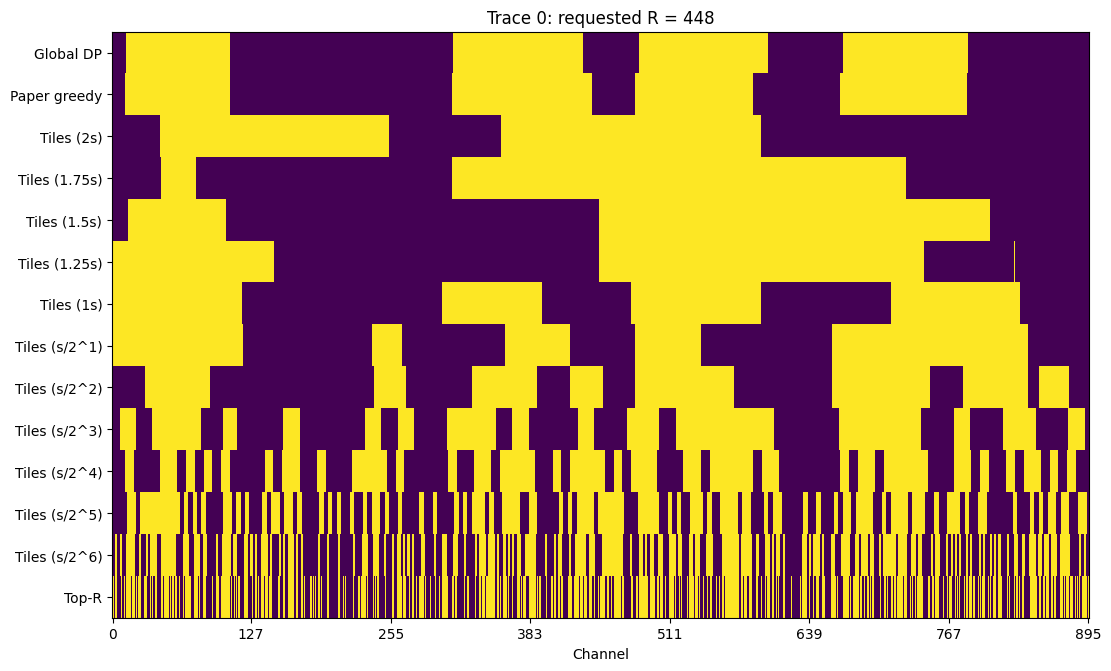

In [7]:
N = int(example.n.iloc[0])
R = int(example.R_nominal.iloc[0])
trace_id = int(example.trace_id.iloc[0])

fig, ax = plt.subplots(
    figsize=(11, 0.4 * len(example) + 1),
    layout="constrained",
)
ax.imshow(
    masks,
    aspect="auto",
    interpolation="nearest",
    cmap="viridis",
    vmin=0,
    vmax=1,
)
ax.set_yticks(range(len(example)), labels=example.index)
ax.set_xticks(np.linspace(0, N - 1, 8, dtype=int))
ax.set(
    xlabel="Channel",
    title=f"Trace {trace_id}: requested R = {R}",
)
plt.show()